# 12 · Capstone: Solving a Kaggle Challenge

[Kaggle](https://www.kaggle.com) hosts machine-learning competitions. This capstone works through one of
its classic *Getting Started* challenges, **House Prices: Advanced Regression Techniques**: predict the sale
price of homes in Ames, Iowa from 79 descriptive variables. The workflow is the one every serious project
follows: understand the data and the metric, set a baseline, engineer features, validate properly, compare
models, and only then predict.

**You will learn**
1. Where the data comes from and whether you may use it (licensing)
2. The competition metric, and why it is computed on log prices
3. Exploration that changes decisions: skew, outliers, the strongest predictors
4. Baselines, then a scikit-learn `Pipeline` with feature engineering
5. Cross-validation, model comparison and blending
6. What drives the predictions, and how you would submit to Kaggle

## 1. The data, and whether we may use it
Kaggle datasets carry their own licences, and **competition data is governed by the competition's rules**,
which usually allow use only for the competition and forbid redistribution. A course should therefore not
re-host Kaggle's competition files.

This competition's data is a subset of the **Ames Housing dataset**, which Dean De Cock compiled
specifically for teaching and published with the *Journal of Statistics Education* (2011). The full dataset
(2,930 sales from 2006 to 2010) is openly available, here through [OpenML](https://www.openml.org/d/43926)
(licence: public). We use that, credit it, and leave the competition files on Kaggle, where you can
download them with your own account to submit.

> De Cock, D. (2011). *Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression
> Project.* Journal of Statistics Education, 19(3).

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

ames = fetch_openml(data_id=43926, as_frame=True, parser="auto").frame   # downloaded once, then cached
print(ames.shape)
ames[["Neighborhood", "Gr_Liv_Area", "Overall_Qual", "Year_Built", "Total_Bsmt_SF", "Garage_Cars", "Sale_Price"]].head()

(2930, 81)


,Neighborhood,Gr_Liv_Area,Overall_Qual,Year_Built,Total_Bsmt_SF,Garage_Cars,Sale_Price
0,North_Ames,1656,Above_Average,1960,1080,2,215000
1,North_Ames,896,Average,1961,882,1,105000
2,North_Ames,1329,Above_Average,1958,1329,1,172000
3,North_Ames,2110,Good,1968,2110,2,244000
4,Gilbert,1629,Average,1997,928,2,189900


## 2. The metric
The competition scores the **root mean squared error between the logarithms** of predicted and actual
prices. On a log scale an error of 10% costs the same for a cheap and an expensive house, which matches
how a buyer thinks about a bad estimate. So we model `log(price)` directly.

We hold out 25% of the sales as a private "leaderboard" that is touched only once, at the end.

train 2197, held-out test 733


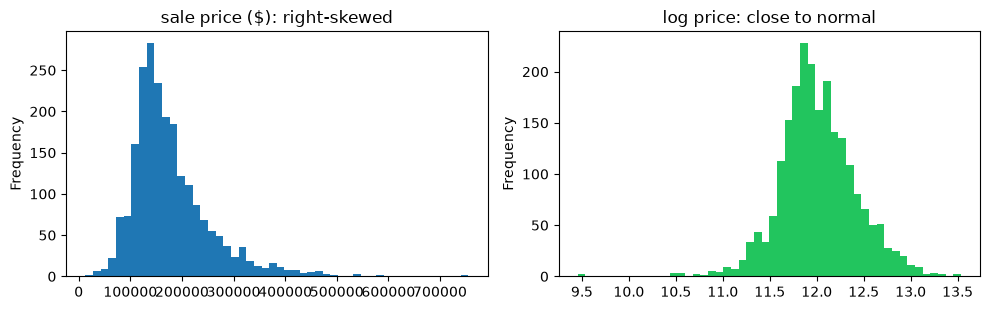

In [2]:
from sklearn.model_selection import train_test_split

def rmse_log(y_true_log, y_pred_log):
    return float(np.sqrt(np.mean((np.asarray(y_true_log) - np.asarray(y_pred_log)) ** 2)))

df = ames.copy()
df["log_price"] = np.log(df.pop("Sale_Price"))
train, test = train_test_split(df, test_size=0.25, random_state=42)
print(f"train {len(train)}, held-out test {len(test)}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
np.exp(train["log_price"]).plot.hist(bins=50, ax=ax[0], title="sale price ($): right-skewed")
train["log_price"].plot.hist(bins=50, ax=ax[1], title="log price: close to normal", color="#22c55e")
plt.tight_layout(); plt.show()

## 3. Exploration that changes decisions

strongest numeric correlations with log price:
 Gr_Liv_Area       0.68
Garage_Cars       0.66
Garage_Area       0.63
Total_Bsmt_SF     0.61
Year_Built        0.60
First_Flr_SF      0.59
Full_Bath         0.57
Year_Remod_Add    0.57


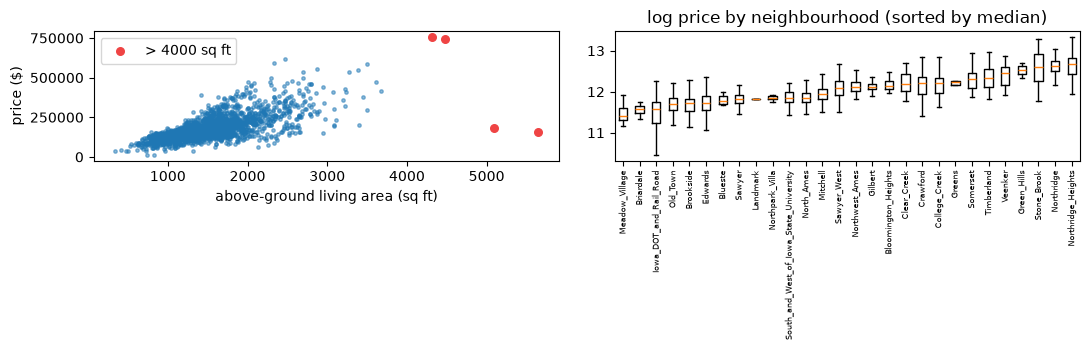

In [3]:
num = train.select_dtypes("number")
top = num.corr()["log_price"].drop("log_price").sort_values(key=abs, ascending=False).head(8)
print("strongest numeric correlations with log price:\n", top.round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].scatter(train["Gr_Liv_Area"], np.exp(train["log_price"]), s=6, alpha=.5)
big = train["Gr_Liv_Area"] > 4000
ax[0].scatter(train.loc[big, "Gr_Liv_Area"], np.exp(train.loc[big, "log_price"]), s=30, color="#ef4444", label="> 4000 sq ft")
ax[0].set_xlabel("above-ground living area (sq ft)"); ax[0].set_ylabel("price ($)"); ax[0].legend()
order = train.groupby("Neighborhood", observed=True)["log_price"].median().sort_values().index
ax[1].boxplot([train.loc[train["Neighborhood"] == n, "log_price"] for n in order], showfliers=False)
ax[1].set_xticks(range(1, len(order) + 1)); ax[1].set_xticklabels(order, rotation=90, fontsize=6)
ax[1].set_title("log price by neighbourhood (sorted by median)")
plt.tight_layout(); plt.show()

Two findings shape the model:
- **Size and quality dominate**, and neighbourhood shifts the whole price level.
- A few **very large houses sold at low prices** (red, partial sales of unusual properties). De Cock's own
  documentation recommends removing houses above 4,000 sq ft for teaching models; we drop them from
  *training* only, never from the test set.

## 4. Baselines
Every model must beat something simple. The median price, and a one-variable regression on living area:

In [4]:
from sklearn.linear_model import LinearRegression

train = train[train["Gr_Liv_Area"] <= 4000]
y_train, y_test = train["log_price"], test["log_price"]

print(f"predict the median        : RMSE(log) {rmse_log(y_test, np.full(len(test), y_train.median())):.4f}")
lr = LinearRegression().fit(np.log(train[["Gr_Liv_Area"]]), y_train)
print(f"log(area) linear regression: RMSE(log) {rmse_log(y_test, lr.predict(np.log(test[['Gr_Liv_Area']]))):.4f}")

predict the median        : RMSE(log) 0.4244
log(area) linear regression: RMSE(log) 0.2797


## 5. Feature engineering inside a Pipeline
Feature engineering written as a function inside a scikit-learn `Pipeline` is applied identically to
training data, validation folds and new houses, which prevents the most common competition bug: leaking
information from the data you evaluate on.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

QUALITY = ["Very_Poor", "Poor", "Fair", "Below_Average", "Average", "Above_Average", "Good",
           "Very_Good", "Excellent", "Very_Excellent"]
GRADE = {"No_Basement": 0, "No_Garage": 0, "No_Fireplace": 0, "No_Pool": 0, "Poor": 1, "Fair": 2,
         "Typical": 3, "Good": 4, "Excellent": 5}

def engineer(X: pd.DataFrame) -> pd.DataFrame:
    X = X.drop(columns=["log_price"], errors="ignore").copy()
    X["Overall_Qual_n"] = X["Overall_Qual"].astype(str).map({q: i for i, q in enumerate(QUALITY, 1)})
    for col in ["Exter_Qual", "Kitchen_Qual", "Bsmt_Qual", "Heating_QC", "Fireplace_Qu", "Garage_Qual"]:
        X[col + "_n"] = X[col].astype(str).map(GRADE).fillna(0)
    X["Total_SF"] = X["Total_Bsmt_SF"] + X["First_Flr_SF"] + X["Second_Flr_SF"]
    X["Total_Baths"] = X["Full_Bath"] + 0.5 * X["Half_Bath"] + X["Bsmt_Full_Bath"] + 0.5 * X["Bsmt_Half_Bath"]
    X["Age_At_Sale"] = X["Year_Sold"] - X["Year_Built"]
    X["Years_Since_Remodel"] = X["Year_Sold"] - X["Year_Remod_Add"]
    X["Qual_x_Area"] = X["Overall_Qual_n"] * X["Gr_Liv_Area"]
    for col in ["Gr_Liv_Area", "Total_SF", "Lot_Area"]:
        X["log_" + col] = np.log1p(X[col])
    return X

fe = FunctionTransformer(engineer)
X_tr_preview = engineer(train)
print(f"{X_tr_preview.shape[1]} columns after engineering; new: "
      f"{[c for c in X_tr_preview.columns if c not in ames.columns]}")

95 columns after engineering; new: ['Overall_Qual_n', 'Exter_Qual_n', 'Kitchen_Qual_n', 'Bsmt_Qual_n', 'Heating_QC_n', 'Fireplace_Qu_n', 'Garage_Qual_n', 'Total_SF', 'Total_Baths', 'Age_At_Sale', 'Years_Since_Remodel', 'Qual_x_Area', 'log_Gr_Liv_Area', 'log_Total_SF', 'log_Lot_Area']


In [6]:
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import HistGradientBoostingRegressor

numeric = make_column_selector(dtype_include="number")
categorical = make_column_selector(dtype_exclude="number")

ridge = make_pipeline(
    fe,
    ColumnTransformer([("num", StandardScaler(), numeric),
                       ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), categorical)]),
    RidgeCV(alphas=np.logspace(-1, 3, 30)),
)

from sklearn.preprocessing import OrdinalEncoder

# Trees take categories as integer codes. The encoder is fitted on the training data only, so a category
# always gets the same code in training, validation and test (codes taken from each DataFrame's own
# pandas categories would not be consistent), and an unseen category becomes "missing".
cat_cols = list(X_tr_preview.select_dtypes(exclude="number").columns)
gbm = make_pipeline(
    fe,
    ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                                              encoded_missing_value=np.nan), cat_cols)],
                      remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas"),
    HistGradientBoostingRegressor(learning_rate=0.05, max_iter=600, max_leaf_nodes=15, min_samples_leaf=10,
                                  l2_regularization=1.0, categorical_features=cat_cols, random_state=0),
)

## 6. Cross-validation and comparison
Five-fold cross-validation on the training set estimates how each model would score on unseen houses,
without touching the held-out test set.

In [7]:
from sklearn.model_selection import KFold, cross_val_predict

cv = KFold(5, shuffle=True, random_state=0)
oof = {}
for name, model in {"Ridge (linear)": ridge, "Gradient boosting": gbm}.items():
    oof[name] = cross_val_predict(model, train, y_train, cv=cv)
    print(f"{name:<20} CV RMSE(log) {rmse_log(y_train, oof[name]):.4f}")

weights = np.linspace(0, 1, 21)
blend_scores = [rmse_log(y_train, w * oof["Ridge (linear)"] + (1 - w) * oof["Gradient boosting"]) for w in weights]
w_best = float(weights[int(np.argmin(blend_scores))])
print(f"best blend: {w_best:.2f} x Ridge + {1 - w_best:.2f} x boosting -> CV RMSE(log) {min(blend_scores):.4f}")

Ridge (linear)       CV RMSE(log) 0.1171


Gradient boosting    CV RMSE(log) 0.1188
best blend: 0.55 x Ridge + 0.45 x boosting -> CV RMSE(log) 0.1137


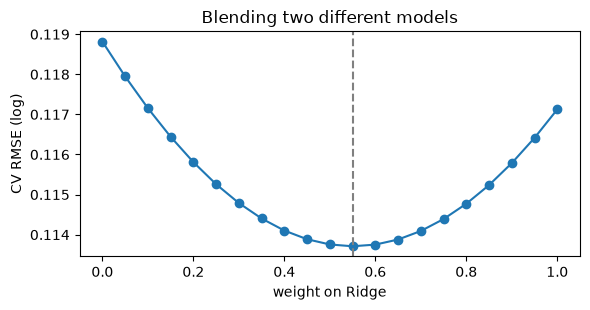

In [8]:
plt.figure(figsize=(6, 3.2))
plt.plot(weights, blend_scores, "o-"); plt.axvline(w_best, ls="--", color="grey")
plt.xlabel("weight on Ridge"); plt.ylabel("CV RMSE (log)"); plt.title("Blending two different models")
plt.tight_layout(); plt.show()

The linear model and the tree ensemble make different kinds of mistakes, so averaging them beats either
one alone. That is the most reliable trick in tabular competitions.

## 7. The final, one-time evaluation
Fit both models on the whole training set and score the held-out houses exactly once.

In [9]:
ridge.fit(train, y_train); gbm.fit(train, y_train)
pred = {"Ridge (linear)": ridge.predict(test), "Gradient boosting": gbm.predict(test)}
pred["Blend"] = w_best * pred["Ridge (linear)"] + (1 - w_best) * pred["Gradient boosting"]
board = pd.Series({"median baseline": rmse_log(y_test, np.full(len(test), y_train.median())),
                   "log(area) regression": rmse_log(y_test, lr.predict(np.log(test[["Gr_Liv_Area"]]))),
                   **{k: rmse_log(y_test, v) for k, v in pred.items()}}).sort_values()
print("held-out RMSE(log), lower is better:\n", board.round(4).to_string())
err = np.exp(pred["Blend"]) / np.exp(y_test) - 1
print(f"\nblend: median absolute error {np.median(np.abs(err)):.1%} of the price; "
      f"80% of houses within {np.quantile(np.abs(err), .8):.1%}")

held-out RMSE(log), lower is better:
 Blend                   0.1101
Gradient boosting       0.1108
Ridge (linear)          0.1167
log(area) regression    0.2797
median baseline         0.4244

blend: median absolute error 5.2% of the price; 80% of houses within 9.8%


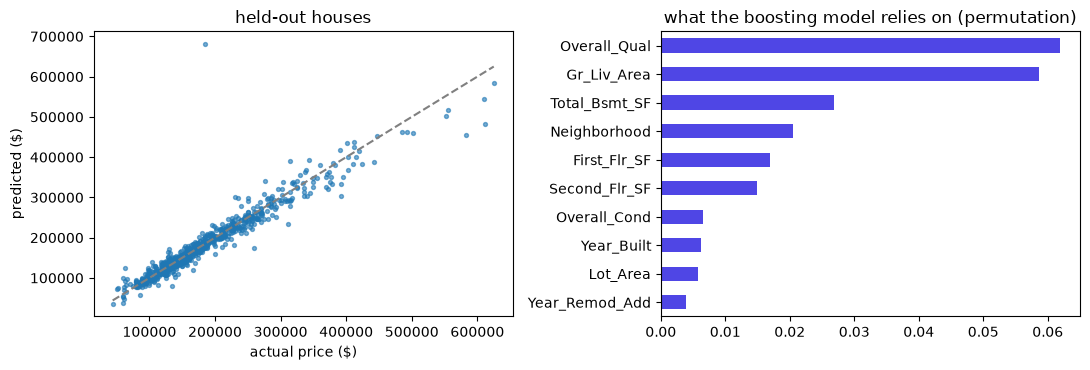

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(np.exp(y_test), np.exp(pred["Blend"]), s=8, alpha=.6)
lims = [np.exp(y_test).min(), np.exp(y_test).max()]
ax[0].plot(lims, lims, "--", color="grey"); ax[0].set_xlabel("actual price ($)"); ax[0].set_ylabel("predicted ($)")
ax[0].set_title("held-out houses")

from sklearn.inspection import permutation_importance
X_test_only = test.drop(columns="log_price")
imp = permutation_importance(gbm, X_test_only, y_test, n_repeats=5, random_state=0, scoring="neg_root_mean_squared_error")
top = pd.Series(imp.importances_mean, index=X_test_only.columns).sort_values().tail(10)
top.plot.barh(ax=ax[1], color="#4f46e5"); ax[1].set_title("what the boosting model relies on (permutation)")
plt.tight_layout(); plt.show()

## 8. Submitting to Kaggle
A Kaggle submission is a CSV with one row per house in the competition's test file: `Id,SalePrice`. This is
how you would produce it:

In [11]:
submission = pd.DataFrame({"Id": range(1, len(test) + 1), "SalePrice": np.exp(pred["Blend"]).round(0)})
print(submission.head().to_string(index=False))

 Id  SalePrice
  1   163755.0
  2   109983.0
  3   188201.0
  4   123558.0
  5   106777.0


To compete for real:
1. Create a Kaggle account, open the *House Prices: Advanced Regression Techniques* competition and
   **accept its rules**; then download `train.csv` and `test.csv` (or use the `kaggle` command-line tool).
2. The competition files use different column spellings (`GrLivArea` instead of `Gr_Liv_Area`) and some
   different category codes, and they mark "no basement" and similar as missing values. Rename the columns,
   fill those values, and reuse the same pipeline.
3. Fit on all of Kaggle's training data, predict `test.csv`, write `submission.csv`, and upload it.

Scores around 0.12 RMSE(log) are typical for a solid blended model like this one; the top of the
leaderboard is near 0.10, reached with careful feature work and many blended models.

## What made the difference
| Step | Why it mattered |
|---|---|
| reading the licence | legal, reusable course material |
| modelling log price | matches the metric and tames the skew |
| removing the documented outliers from training | a handful of huge, cheap houses distort a linear model |
| features in a Pipeline | identical processing everywhere, no leakage |
| cross-validation before the test set | an honest estimate, and the test set stays a true final exam |
| blending different model families | their errors partly cancel |

## Exercises
1. Add `Neighborhood` target encoding (mean log price per neighbourhood, computed inside the cross-validation folds only) and measure the change.
2. Tune the boosting model's `learning_rate` and `max_leaf_nodes` with `RandomizedSearchCV`.
3. Use `Longitude` and `Latitude` (included in this dataset) to add a "distance to the town centre" feature.